## DATA WRANGLING
## Arquivo de apoio para estudo de data wrangling¶

## Notas aula MBA SUP/Esalq - Módulo Data Wrangling III

In [88]:
# IMPORTAÇÃO DE BANCOS DE DADOS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# pip install xlrd # pacote dependência que read_excel usa para ler arquivos na extensão .xls

In [2]:
dados_wdi = pd.read_excel("(2.2) WDI World Bank.xlsx", na_values='..')
dados_grupo = pd.read_excel('(2.3) WDI Income Group.xlsx')
dados_paises = pd.read_excel('(2.4) WDI Country.xlsx')

In [3]:
dados_wdi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 383577 entries, 0 to 383576
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Country Name   383574 non-null  object 
 1   Country Code   383572 non-null  object 
 2   Series Name    383572 non-null  object 
 3   Series Code    383572 non-null  object 
 4   2021 [YR2021]  108687 non-null  float64
 5   Topic          383572 non-null  object 
dtypes: float64(1), object(5)
memory usage: 17.6+ MB


In [4]:
#Verificando elementos únicos das variáveis
len(dados_wdi["Country Name"].unique())

269

In [5]:
#Verificando elementos únicos das variáveis
len(dados_wdi["Series Name"].unique())

1443

In [6]:
#Verificando elementos únicos das variáveis
len(dados_wdi["Topic"].unique())

90

In [7]:
dados_wdi.columns

Index(['Country Name', 'Country Code', 'Series Name', 'Series Code',
       '2021 [YR2021]', 'Topic'],
      dtype='object')

In [8]:
#Alterar nome das variáveis
dados_wdi.rename(columns={"Country Name":"pais","Country Code":"cod_pais","Series Name":"serie",\
                          "2021 [YR2021]":"ano_2021","Topic":"topico"},inplace=True)

In [9]:
# analisando as últimas linhas do dataset

dados_wdi.tail(n=20)

,pais,cod_pais,serie,Series Code,ano_2021,topico
383557,World,WLD,"Water productivity, total (constant 2015 US$ G...",ER.GDP.FWTL.M3.KD,NaN,Environment: Freshwater
383558,World,WLD,Wholesale price index (2010 = 100),FP.WPI.TOTL,NaN,Financial Sector: Exchange rates & prices
383559,World,WLD,Women Business and the Law Index Score (scale ...,SG.LAW.INDX,76.546053,Gender: Public life & decision making
383560,World,WLD,Women making their own informed decisions rega...,SG.DMK.SRCR.FN.ZS,NaN,Gender: Public life & decision making
383561,World,WLD,Women participating in the three decisions (ow...,SG.DMK.ALLD.FN.ZS,NaN,Gender: Public life & decision making
383562,World,WLD,Women who believe a husband is justified in be...,SG.VAW.REAS.ZS,NaN,Gender: Health
383563,World,WLD,Women who believe a husband is justified in be...,SG.VAW.ARGU.ZS,NaN,Gender: Health
383564,World,WLD,Women who believe a husband is justified in be...,SG.VAW.BURN.ZS,NaN,Gender: Health
383565,World,WLD,Women who believe a husband is justified in be...,SG.VAW.GOES.ZS,NaN,Gender: Health
383566,World,WLD,Women who believe a husband is justified in be...,SG.VAW.NEGL.ZS,NaN,Gender: Health


In [10]:
# retirar as últimas linhas, são referências, não observações
dados_wdi = dados_wdi.iloc[0:383572,]

In [11]:
dados_wdi.tail(n=20)

,pais,cod_pais,serie,Series Code,ano_2021,topico
383552,World,WLD,"Vulnerable employment, total (% of total emplo...",SL.EMP.VULN.ZS,NaN,Social Protection & Labor: Economic activity
383553,World,WLD,"Wage and salaried workers, female (% of female...",SL.EMP.WORK.FE.ZS,NaN,Social Protection & Labor: Economic activity
383554,World,WLD,"Wage and salaried workers, male (% of male emp...",SL.EMP.WORK.MA.ZS,NaN,Social Protection & Labor: Economic activity
383555,World,WLD,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,Social Protection & Labor: Economic activity
383556,World,WLD,Wanted fertility rate (births per woman),SP.DYN.WFRT,NaN,Health: Reproductive health
383557,World,WLD,"Water productivity, total (constant 2015 US$ G...",ER.GDP.FWTL.M3.KD,NaN,Environment: Freshwater
383558,World,WLD,Wholesale price index (2010 = 100),FP.WPI.TOTL,NaN,Financial Sector: Exchange rates & prices
383559,World,WLD,Women Business and the Law Index Score (scale ...,SG.LAW.INDX,76.546053,Gender: Public life & decision making
383560,World,WLD,Women making their own informed decisions rega...,SG.DMK.SRCR.FN.ZS,NaN,Gender: Public life & decision making
383561,World,WLD,Women participating in the three decisions (ow...,SG.DMK.ALLD.FN.ZS,NaN,Gender: Public life & decision making


In [12]:
# Selecionando os tópicos de saúde
dados_saude = dados_wdi[dados_wdi["topico"].str.startswith("Health")]

In [13]:
dados_saude

,pais,cod_pais,serie,Series Code,ano_2021,topico
50,Afghanistan,AFG,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,NaN,Health: Reproductive health
54,Afghanistan,AFG,Adults (ages 15+) and children (ages 0-14) new...,SH.HIV.INCD.TL,1500.000000,Health: Risk factors
55,Afghanistan,AFG,Adults (ages 15-49) newly infected with HIV,SH.HIV.INCD,1300.000000,Health: Risk factors
56,Afghanistan,AFG,Age dependency ratio (% of working-age populat...,SP.POP.DPND,84.599257,Health: Population: Dynamics
57,Afghanistan,AFG,"Age dependency ratio, old (% of working-age po...",SP.POP.DPND.OL,4.437872,Health: Population: Dynamics
...,...,...,...,...,...,...
383547,World,WLD,Use of insecticide-treated bed nets (% of unde...,SH.MLR.NETS.ZS,NaN,Health: Disease prevention
383549,World,WLD,Vitamin A supplementation coverage rate (% of ...,SN.ITK.VITA.ZS,NaN,Health: Nutrition
383556,World,WLD,Wanted fertility rate (births per woman),SP.DYN.WFRT,NaN,Health: Reproductive health
383570,World,WLD,Women's share of population ages 15+ living wi...,SH.DYN.AIDS.FE.ZS,53.800000,Health: Risk factors


In [14]:
# função pd.pivot permite reorganizar o banco de dados ajustando indez, columns, values)
dados_saude = pd.pivot(dados_saude,index=["pais","cod_pais"],columns=["serie"],values="ano_2021")

In [15]:
# Voltando para o índice numérico
dados_saude.reset_index(inplace=True)

In [16]:
dados_saude

serie,pais,cod_pais,ARI treatment (% of children under 5 taken to a health provider),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15-49) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Antiretroviral therapy coverage (% of people living with HIV),...,"Total alcohol consumption per capita, male (liters of pure alcohol, projected estimates, male 15+ years of age)","Tuberculosis case detection rate (%, all forms)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,Unmet need for contraception (% of married women ages 15-49),Use of insecticide-treated bed nets (% of under-5 population),Vitamin A supplementation coverage rate (% of children ages 6-59 months),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV
0,Afghanistan,AFG,NaN,NaN,1500.0,1300.0,84.599257,4.437872,80.161385,10.000000,...,NaN,66.0,NaN,NaN,NaN,NaN,NaN,NaN,29.100000,500.0
1,Africa Eastern and Southern,AFE,NaN,NaN,NaN,NaN,81.190004,5.706194,74.565174,79.370724,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.535130,NaN
2,Africa Western and Central,AFW,NaN,NaN,NaN,NaN,85.495451,5.337003,79.773361,77.519787,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.923126,NaN
3,Albania,ALB,NaN,NaN,100.0,100.0,48.183223,24.056432,24.126791,53.000000,...,NaN,56.0,NaN,NaN,NaN,NaN,NaN,NaN,26.600000,100.0
4,Algeria,DZA,NaN,NaN,2000.0,1600.0,58.463731,9.796228,48.667504,82.000000,...,NaN,79.0,NaN,NaN,NaN,NaN,NaN,NaN,46.900000,200.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,West Bank and Gaza,PSE,NaN,NaN,NaN,NaN,74.282354,6.072615,68.209739,NaN,...,NaN,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
262,World,WLD,NaN,NaN,1500000.0,1200000.0,55.289803,14.821066,39.291501,75.000000,...,NaN,61.0,NaN,NaN,NaN,NaN,NaN,NaN,53.800000,400000.0
263,"Yemen, Rep.",YEM,NaN,NaN,1100.0,1000.0,74.098178,4.681567,69.416611,31.000000,...,NaN,59.0,NaN,NaN,NaN,NaN,NaN,NaN,34.400000,200.0
264,Zambia,ZMB,NaN,NaN,38000.0,32000.0,81.822456,3.161765,78.660691,90.000000,...,NaN,84.0,NaN,NaN,NaN,NaN,NaN,NaN,61.900000,15000.0


In [27]:
dados_paises.columns

Index(['cod_pais', 'Name'], dtype='object')

In [26]:
dados_paises.rename(columns={"Country":"cod_pais"},inplace=True)

In [28]:
# realizar merge com dados_paises após ajustar o nome da variável
dados_saude = pd.merge(dados_saude,dados_paises,how="left",on="cod_pais")

In [29]:
dados_saude

,pais,cod_pais,ARI treatment (% of children under 5 taken to a health provider),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15-49) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Antiretroviral therapy coverage (% of people living with HIV),...,"Tuberculosis case detection rate (%, all forms)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,Unmet need for contraception (% of married women ages 15-49),Use of insecticide-treated bed nets (% of under-5 population),Vitamin A supplementation coverage rate (% of children ages 6-59 months),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV,Name
0,Afghanistan,AFG,NaN,NaN,1500.0,1300.0,84.599257,4.437872,80.161385,10.000000,...,66.0,NaN,NaN,NaN,NaN,NaN,NaN,29.100000,500.0,Islamic State of Afghanistan
1,Africa Eastern and Southern,AFE,NaN,NaN,NaN,NaN,81.190004,5.706194,74.565174,79.370724,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.535130,NaN,NaN
2,Africa Western and Central,AFW,NaN,NaN,NaN,NaN,85.495451,5.337003,79.773361,77.519787,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,62.923126,NaN,NaN
3,Albania,ALB,NaN,NaN,100.0,100.0,48.183223,24.056432,24.126791,53.000000,...,56.0,NaN,NaN,NaN,NaN,NaN,NaN,26.600000,100.0,Republic of Albania
4,Algeria,DZA,NaN,NaN,2000.0,1600.0,58.463731,9.796228,48.667504,82.000000,...,79.0,NaN,NaN,NaN,NaN,NaN,NaN,46.900000,200.0,People's Democratic Republic of Algeria
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,West Bank and Gaza,PSE,NaN,NaN,NaN,NaN,74.282354,6.072615,68.209739,NaN,...,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,West Bank and Gaza
262,World,WLD,NaN,NaN,1500000.0,1200000.0,55.289803,14.821066,39.291501,75.000000,...,61.0,NaN,NaN,NaN,NaN,NaN,NaN,53.800000,400000.0,NaN
263,"Yemen, Rep.",YEM,NaN,NaN,1100.0,1000.0,74.098178,4.681567,69.416611,31.000000,...,59.0,NaN,NaN,NaN,NaN,NaN,NaN,34.400000,200.0,Republic of Yemen
264,Zambia,ZMB,NaN,NaN,38000.0,32000.0,81.822456,3.161765,78.660691,90.000000,...,84.0,NaN,NaN,NaN,NaN,NaN,NaN,61.900000,15000.0,Republic of Zambia


In [30]:
#remover valores nan na variável Name - não são países
dados_saude = dados_saude[~dados_saude["Name"].isna()].reset_index(drop=True)

In [31]:
dados_saude

,pais,cod_pais,ARI treatment (% of children under 5 taken to a health provider),"Adolescent fertility rate (births per 1,000 women ages 15-19)",Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15-49) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Antiretroviral therapy coverage (% of people living with HIV),...,"Tuberculosis case detection rate (%, all forms)",Tuberculosis treatment success rate (% of new cases),UHC service coverage index,Unmet need for contraception (% of married women ages 15-49),Use of insecticide-treated bed nets (% of under-5 population),Vitamin A supplementation coverage rate (% of children ages 6-59 months),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV,Name
0,Afghanistan,AFG,NaN,NaN,1500.0,1300.0,84.599257,4.437872,80.161385,10.0,...,66.0,NaN,NaN,NaN,NaN,NaN,NaN,29.1,500.0,Islamic State of Afghanistan
1,Albania,ALB,NaN,NaN,100.0,100.0,48.183223,24.056432,24.126791,53.0,...,56.0,NaN,NaN,NaN,NaN,NaN,NaN,26.6,100.0,Republic of Albania
2,Algeria,DZA,NaN,NaN,2000.0,1600.0,58.463731,9.796228,48.667504,82.0,...,79.0,NaN,NaN,NaN,NaN,NaN,NaN,46.9,200.0,People's Democratic Republic of Algeria
3,American Samoa,ASM,NaN,NaN,NaN,NaN,52.335690,10.425194,41.910496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,American Samoa
4,Andorra,AND,NaN,NaN,NaN,NaN,38.140600,20.079704,18.060896,NaN,...,87.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Principality of Andorra
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,NaN,NaN,NaN,NaN,64.603999,32.928574,31.675425,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Virgin Islands of the United States
213,West Bank and Gaza,PSE,NaN,NaN,NaN,NaN,74.282354,6.072615,68.209739,NaN,...,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,West Bank and Gaza
214,"Yemen, Rep.",YEM,NaN,NaN,1100.0,1000.0,74.098178,4.681567,69.416611,31.0,...,59.0,NaN,NaN,NaN,NaN,NaN,NaN,34.4,200.0,Republic of Yemen
215,Zambia,ZMB,NaN,NaN,38000.0,32000.0,81.822456,3.161765,78.660691,90.0,...,84.0,NaN,NaN,NaN,NaN,NaN,NaN,61.9,15000.0,Republic of Zambia


In [32]:
#remover a coluna que não será mais usada
dados_saude.drop(columns=["Name"], inplace=True)

In [42]:
# remover variáveis que apresentam apenas NaN
# axix=1 refere-se às colunas
# how = "all" drop se todos os elementos forem "NaN"
dados_saude.dropna(axis=1,how="all",inplace=True)

In [51]:
# Adicionar variáveis específicas de um data set a outro
# Neste caso vamos adicionar "Income Group", que está no data set dados_grupo
# Iniciamos fazendo uma cópia da variável de interesse
# Alteramos o nome da chave para a ligação entre DataFrames
# A seguir realizamos o merge
dados_grupo_select = dados_grupo[["Code","Income Group"]].copy()
dados_grupo_select.rename(columns={"Code":"cod_pais"},inplace=True)
dados_saude = pd.merge(dados_saude,dados_grupo_select,how="left",on="cod_pais")
dados_saude

,pais,cod_pais,ARI treatment (% of children under 5 taken to a health provider),Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15-49) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Antiretroviral therapy coverage (% of people living with HIV),Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV),...,"Probability of dying among youth ages 20-24 years (per 1,000)",Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant),"Tuberculosis case detection rate (%, all forms)",Unmet need for contraception (% of married women ages 15-49),Use of insecticide-treated bed nets (% of under-5 population),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV,Income Group_x,Income Group_y
0,Afghanistan,AFG,NaN,1500.0,1300.0,84.599257,4.437872,80.161385,10.0,16.0,...,17.8,NaN,66.0,NaN,NaN,NaN,29.1,500.0,Low income,Low income
1,Albania,ALB,NaN,100.0,100.0,48.183223,24.056432,24.126791,53.0,NaN,...,1.9,NaN,56.0,NaN,NaN,NaN,26.6,100.0,Upper middle income,Upper middle income
2,Algeria,DZA,NaN,2000.0,1600.0,58.463731,9.796228,48.667504,82.0,16.0,...,3.0,NaN,79.0,NaN,NaN,NaN,46.9,200.0,Lower middle income,Lower middle income
3,American Samoa,ASM,NaN,NaN,NaN,52.335690,10.425194,41.910496,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Upper middle income,Upper middle income
4,Andorra,AND,NaN,NaN,NaN,38.140600,20.079704,18.060896,NaN,NaN,...,1.9,NaN,87.0,NaN,NaN,NaN,NaN,NaN,High income,High income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,NaN,NaN,NaN,64.603999,32.928574,31.675425,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,High income,High income
213,West Bank and Gaza,PSE,NaN,NaN,NaN,74.282354,6.072615,68.209739,NaN,NaN,...,4.2,NaN,80.0,NaN,NaN,NaN,NaN,NaN,Lower middle income,Lower middle income
214,"Yemen, Rep.",YEM,NaN,1100.0,1000.0,74.098178,4.681567,69.416611,31.0,NaN,...,13.3,NaN,59.0,NaN,NaN,NaN,34.4,200.0,Low income,Low income
215,Zambia,ZMB,NaN,38000.0,32000.0,81.822456,3.161765,78.660691,90.0,97.0,...,11.9,NaN,84.0,NaN,NaN,NaN,61.9,15000.0,Low income,Low income


In [55]:
# Reorganizar a posição da coluna
# Remocer a variável de interesse
organizar = dados_saude.pop("Income Group_y")

In [ ]:
# inserir na posição desejada
dados_saude.insert(2,"Group",organizar)

In [61]:
dados_saude

,pais,cod_pais,Group,ARI treatment (% of children under 5 taken to a health provider),Adults (ages 15+) and children (ages 0-14) newly infected with HIV,Adults (ages 15-49) newly infected with HIV,Age dependency ratio (% of working-age population),"Age dependency ratio, old (% of working-age population)","Age dependency ratio, young (% of working-age population)",Antiretroviral therapy coverage (% of people living with HIV),...,"Probability of dying among adolescents ages 15-19 years (per 1,000)","Probability of dying among children ages 5-9 years (per 1,000)","Probability of dying among youth ages 20-24 years (per 1,000)",Teenage mothers (% of women ages 15-19 who have had children or are currently pregnant),"Tuberculosis case detection rate (%, all forms)",Unmet need for contraception (% of married women ages 15-49),Use of insecticide-treated bed nets (% of under-5 population),Wanted fertility rate (births per woman),Women's share of population ages 15+ living with HIV (%),Young people (ages 15-24) newly infected with HIV
0,Afghanistan,AFG,Low income,NaN,1500.0,1300.0,84.599257,4.437872,80.161385,10.0,...,12.7,2.3,17.8,NaN,66.0,NaN,NaN,NaN,29.1,500.0
1,Albania,ALB,Upper middle income,NaN,100.0,100.0,48.183223,24.056432,24.126791,53.0,...,1.6,0.8,1.9,NaN,56.0,NaN,NaN,NaN,26.6,100.0
2,Algeria,DZA,Lower middle income,NaN,2000.0,1600.0,58.463731,9.796228,48.667504,82.0,...,2.4,1.4,3.0,NaN,79.0,NaN,NaN,NaN,46.9,200.0
3,American Samoa,ASM,Upper middle income,NaN,NaN,NaN,52.335690,10.425194,41.910496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Andorra,AND,High income,NaN,NaN,NaN,38.140600,20.079704,18.060896,NaN,...,1.3,0.3,1.9,NaN,87.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,High income,NaN,NaN,NaN,64.603999,32.928574,31.675425,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
213,West Bank and Gaza,PSE,Lower middle income,NaN,NaN,NaN,74.282354,6.072615,68.209739,NaN,...,3.4,1.7,4.2,NaN,80.0,NaN,NaN,NaN,NaN,NaN
214,"Yemen, Rep.",YEM,Low income,NaN,1100.0,1000.0,74.098178,4.681567,69.416611,31.0,...,8.4,4.4,13.3,NaN,59.0,NaN,NaN,NaN,34.4,200.0
215,Zambia,ZMB,Low income,NaN,38000.0,32000.0,81.822456,3.161765,78.660691,90.0,...,8.6,6.5,11.9,NaN,84.0,NaN,NaN,NaN,61.9,15000.0


In [63]:
# Obter as posições das variáveis
# Neste caso a variável de interesse está na posição 23
col_pos = dados_saude.columns

In [66]:
# verificar em que posição está determinada variável
list(enumerate(col_pos))

[(0, 'pais'),
 (1, 'cod_pais'),
 (2, 'Group'),
 (3, 'ARI treatment (% of children under 5 taken to a health provider)'),
 (4, 'Adults (ages 15+) and children (ages 0-14) newly infected with HIV'),
 (5, 'Adults (ages 15-49) newly infected with HIV'),
 (6, 'Age dependency ratio (% of working-age population)'),
 (7, 'Age dependency ratio, old (% of working-age population)'),
 (8, 'Age dependency ratio, young (% of working-age population)'),
 (9, 'Antiretroviral therapy coverage (% of people living with HIV)'),
 (10,
  'Antiretroviral therapy coverage for PMTCT (% of pregnant women living with HIV)'),
 (11, 'Births attended by skilled health staff (% of total)'),
 (12, 'Children (0-14) living with HIV'),
 (13, 'Children (ages 0-14) newly infected with HIV'),
 (14,
  'Children with fever receiving antimalarial drugs (% of children under age 5 with fever)'),
 (15, 'Completeness of birth registration (%)'),
 (16, 'Completeness of birth registration, female (%)'),
 (17, 'Completeness of birth 

In [67]:
# verificar em que posição está determinada variável
dados_saude.columns.get_loc("Diabetes prevalence (% of population ages 20 to 79)")

23

In [68]:
dados_saude.iloc[:,23].describe()

count    212.000000
mean       9.014623
std        5.305360
min        1.100000
25%        5.600000
50%        7.400000
75%       11.150000
max       30.800000
Name: Diabetes prevalence (% of population ages 20 to 79), dtype: float64

In [84]:
# Estatísticas descritivas
estat_grupo = dados_saude.iloc[:,[2,23]].groupby("Group").mean().reset_index()

In [85]:
estat_grupo

,Group,Diabetes prevalence (% of population ages 20 to 79)
0,High income,9.428947
1,Low income,5.967857
2,Lower middle income,8.561111
3,Upper middle income,10.481132


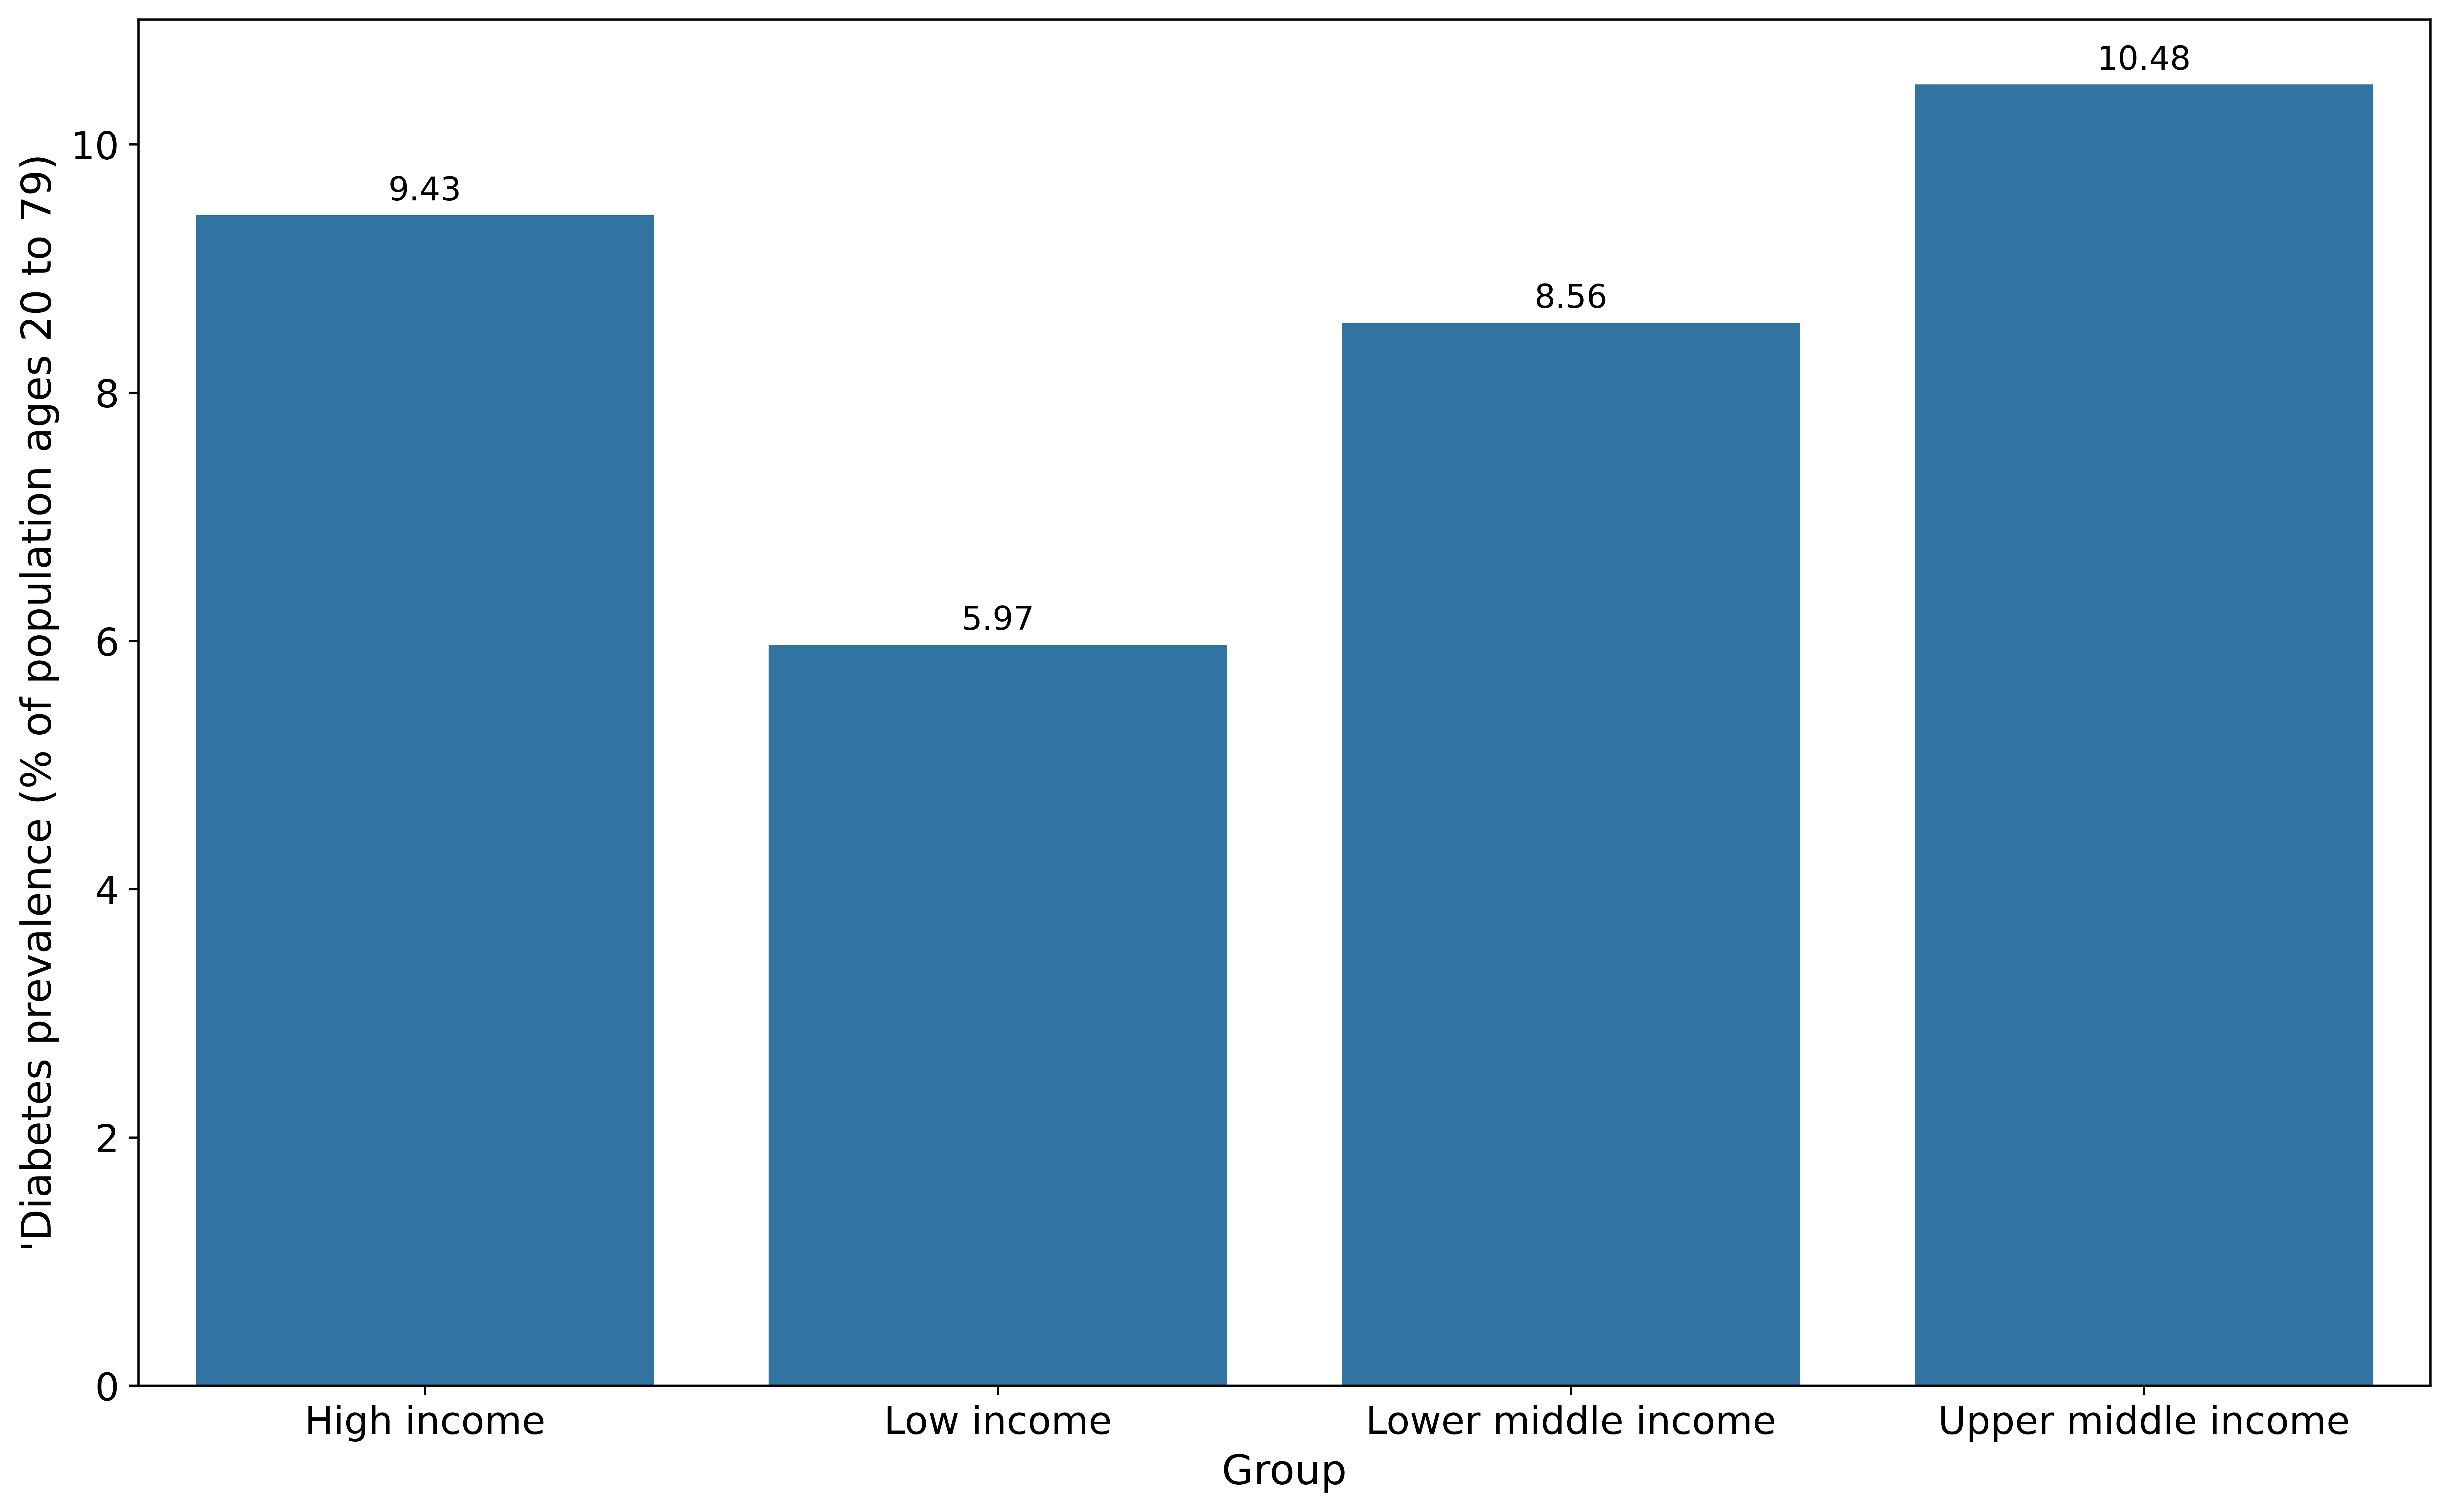

In [95]:
# Gráfico
plt.figure(figsize=(15,9),dpi=600)
ax = sns.barplot(data=estat_grupo,x=estat_grupo.iloc[:,0],y=estat_grupo.iloc[:,1])
for container in ax.containers: ax.bar_label(container,fmt="%.2f",padding=3,fontsize=12)
plt.xlabel("Group",fontsize=15)
plt.ylabel("'Diabetes prevalence (% of population ages 20 to 79)", fontsize=15)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()